In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# perform the usual operation to understand the data

In [93]:
df=pd.read_csv("bank.csv")
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   str    
 2   marital    8743 non-null   str    
 3   education  8885 non-null   str    
 4   default    8908 non-null   str    
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   str    
 7   loan       8882 non-null   str    
 8   contact    8881 non-null   str    
 9   day        8893 non-null   float64
 10  month      8884 non-null   str    
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   str    
 16  deposit    8903 non-null   str    
dtypes: float64(6), int64(1), str(10)
memory usage: 1.6 MB


In [95]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [96]:
df.shape

(8912, 17)

In [97]:
df.isnull().sum().sort_values(ascending=False)

marital      169
pdays        145
contact       31
loan          30
month         28
education     27
day           19
balance       13
housing       13
deposit        9
campaign       8
duration       7
job            7
default        4
previous       3
age            0
poutcome       0
dtype: int64

In [98]:
df.duplicated().sum()

np.int64(0)

###
Your file contains 8,912 rows and 17 columns. Let's understand what each column tells you in simple English.
1. Customer information
Column	What it tells you
age	The customer's age in years.
job	The customer's occupation, such as admin, technician, or management.
marital	The customer's marital status: married, single, or divorced.
education	The customer's education level, such as primary, secondary, or tertiary.
2. Financial information
Column	What it tells you
default	Whether the customer has credit in default — generally, whether they have failed to meet a credit obligation.
balance	The customer's average yearly account balance, typically measured in euros in the original dataset.
housing	Whether the customer has a housing loan (yes or no).
loan	Whether the customer has a personal loan (yes or no).
These columns help you understand the customer's financial situation and existing borrowing commitments.
3. Marketing campaign information
Column	What it tells you
contact	The communication method used to contact the customer, such as cellular or telephone.
day	The day of the month when the customer was last contacted during the campaign.
month	The month when the customer was last contacted.
duration	The duration of the last contact with the customer, measured in seconds.
campaign	The number of contacts made to this customer during the current campaign, including the last contact.
These columns help you understand how the bank contacted customers and how frequently it communicated with them.
4. Previous marketing campaign information
Column	What it tells you
pdays	The number of days since the customer was last contacted in a previous campaign. A value of -1 commonly means the customer was not previously contacted.
previous	The number of contacts made to the customer before the current campaign.
poutcome	The outcome of the previous marketing campaign, such as success, failure, or unknown.
These columns help you investigate whether a customer's previous interactions with the bank affect their response to the current campaign.
5. The target column
Column	What it tells you
deposit	Whether the customer subscribed to a term deposit: yes or no.
This is likely your target column if your task is to predict whether a customer will subscribe to a term deposit.
- yes = the customer subscribed.
- no = the customer did not subscribe.
Because the target has two possible outcomes, this would be a binary classification problem.

# Visualization to understand the relations between the columns and each other

<Axes: xlabel='education', ylabel='deposit'>

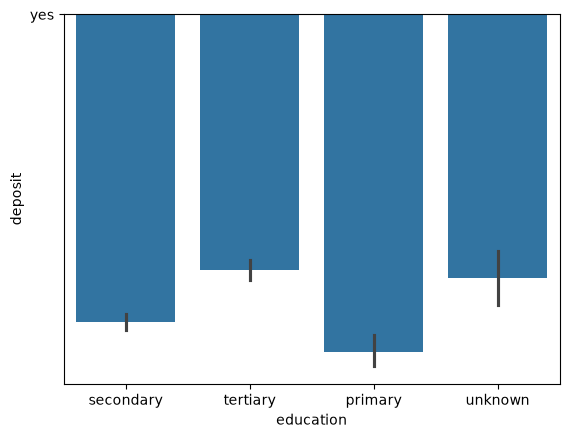

In [99]:
sns.barplot(data=df, x='education',y='deposit')

<Axes: xlabel='campaign', ylabel='deposit'>

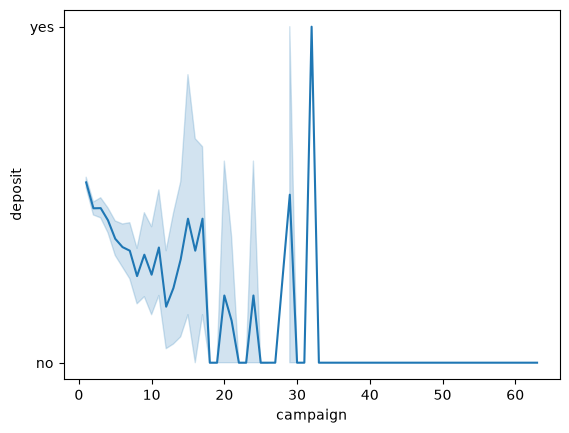

In [100]:
sns.lineplot(data=df, x='campaign',y='deposit')

<Axes: xlabel='marital', ylabel='deposit'>

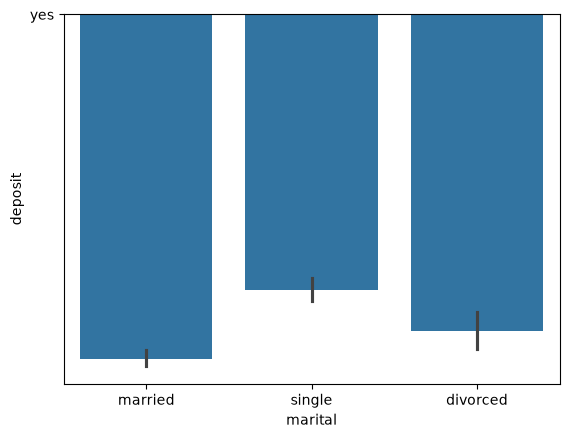

In [101]:
sns.barplot(data=df, x='marital',y='deposit')

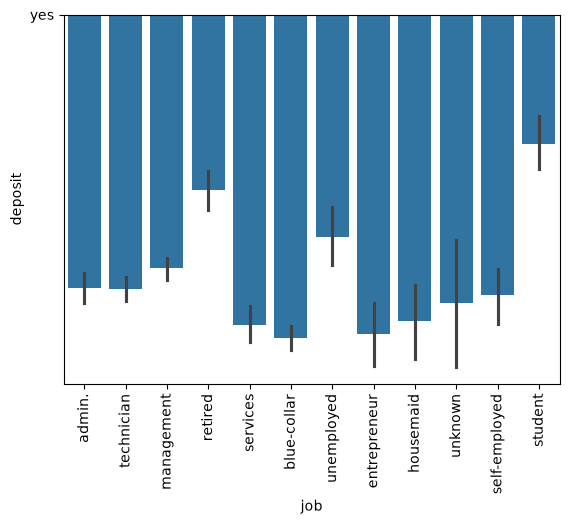

In [102]:
sns.barplot(data=df, x='job',y='deposit')
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='contact', ylabel='deposit'>

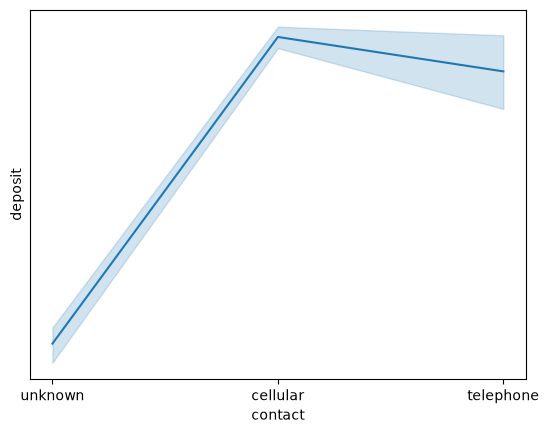

In [103]:
sns.lineplot(data=df, x='contact',y='deposit')

## check the outliers in the numerical columns to determine the strategy to fill the null values 

In [104]:
df.select_dtypes('number').isnull().sum().sort_values(ascending=False)

pdays       145
day          19
balance      13
campaign      8
duration      7
previous      3
age           0
dtype: int64

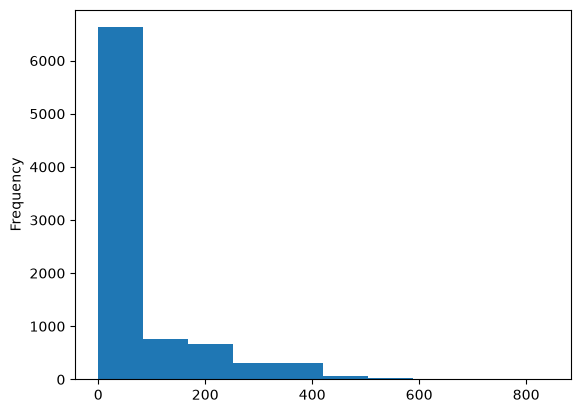

In [105]:
df['pdays'].plot(kind='hist')
plt.show()

In [106]:
df['pdays'].skew() # outliers 
# deal with the -1 value in the columns 

np.float64(2.3600576727470965)

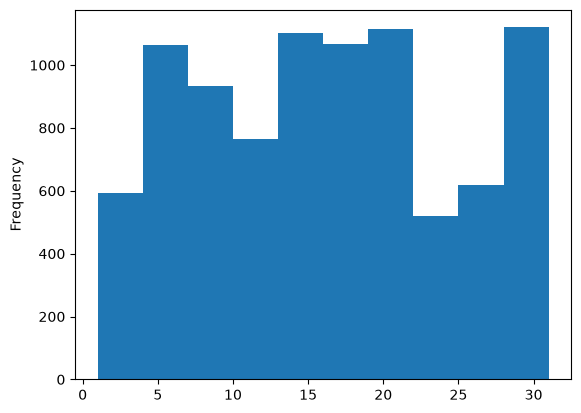

In [107]:
df['day'].plot(kind='hist')
plt.show()

In [108]:
df['day'].skew() # outliers

np.float64(0.10606045955622366)

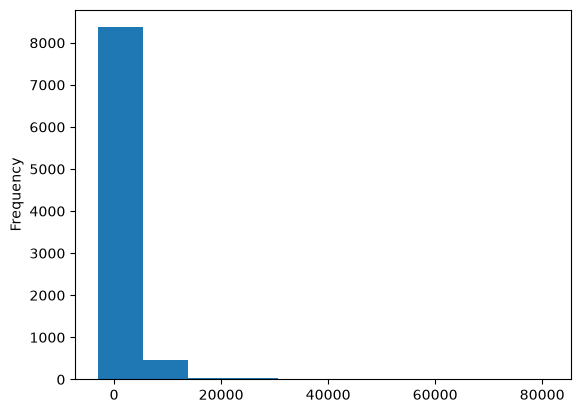

In [109]:
df['balance'].plot(kind='hist')
plt.show()

In [110]:
df['balance'].skew() # outliers

np.float64(8.642050295923712)

<Axes: ylabel='Frequency'>

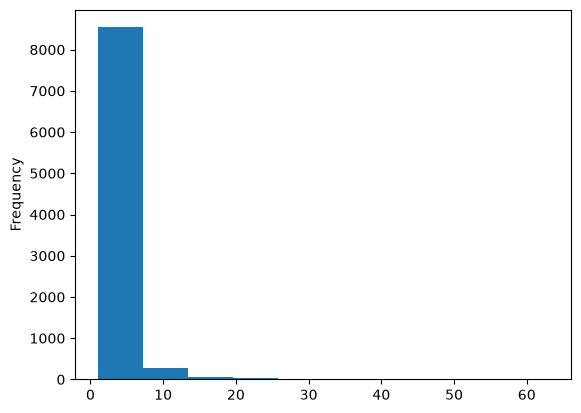

In [111]:
df['campaign'].plot(kind='hist')

In [112]:
df['campaign'].skew() # outliers

np.float64(5.780260195613428)

<Axes: ylabel='Frequency'>

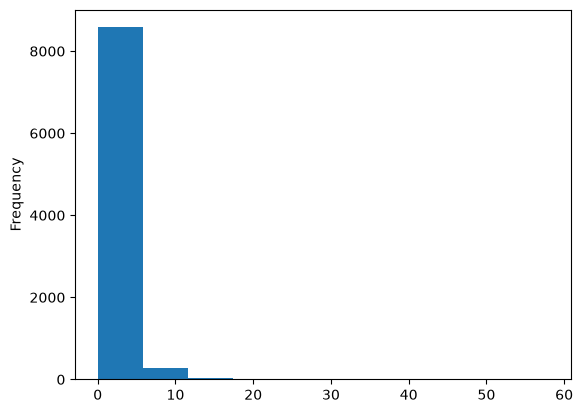

In [113]:
df['previous'].plot(kind='hist')

In [114]:
df['previous'].skew() # outliers

np.float64(7.59159169491129)

# add a new feature to deal with the -1 value in the pdays columns

In [115]:
import numpy as np

df['previously_contacted'] = (df['pdays'] != -1).astype(int)

df['pdays'] = df['pdays'].replace(-1, np.nan)

In [116]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,previously_contacted
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,NaN,0.0,unknown,yes,0
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,NaN,0.0,unknown,yes,0
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,NaN,0.0,unknown,yes,0
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,NaN,0.0,unknown,yes,0
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,NaN,0.0,unknown,yes,0


In [117]:
df.select_dtypes('number').isnull().sum().sort_values(ascending=False)

pdays                   6636
day                       19
balance                   13
campaign                   8
duration                   7
previous                   3
age                        0
previously_contacted       0
dtype: int64

# Removing the null values 

In [118]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='median')
for col in ['pdays','day','balance','previous','campaign','duration']:
    df[[col]]=imputer.fit_transform(df[[col]])

In [119]:
df.select_dtypes('number').isnull().sum().sort_values(ascending=False)

age                     0
balance                 0
day                     0
duration                0
campaign                0
pdays                   0
previous                0
previously_contacted    0
dtype: int64

In [120]:
df.select_dtypes(object).isnull().sum().sort_values(ascending=False)

C:\Users\abdoa\AppData\Local\Temp\ipykernel_13064\3211918508.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(object).isnull().sum().sort_values(ascending=False)


marital      169
contact       31
loan          30
month         28
education     27
housing       13
deposit        9
job            7
default        4
poutcome       0
dtype: int64

In [121]:
df = df.dropna(subset=["deposit"]).copy()

In [122]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for columns in ['marital','contact','loan','month','education','housing','job','default']:
    df[[columns]]=imputer.fit_transform(df[[columns]])

In [123]:
df.select_dtypes(object).isnull().sum().sort_values(ascending=False)

C:\Users\abdoa\AppData\Local\Temp\ipykernel_13064\3211918508.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(object).isnull().sum().sort_values(ascending=False)


job          0
marital      0
education    0
default      0
housing      0
loan         0
contact      0
month        0
poutcome     0
deposit      0
dtype: int64

In [124]:
df.dropna(inplace=True)

In [125]:
df.reset_index(drop=True,inplace=True)

# Encoding, Outliers, Spliting, and Scaling

In [126]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,previously_contacted
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,182.0,0.0,unknown,yes,0
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,182.0,0.0,unknown,yes,0
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,182.0,0.0,unknown,yes,0
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,182.0,0.0,unknown,yes,0
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,182.0,0.0,unknown,yes,0


In [127]:
cols = df.select_dtypes(include='object').columns

for col in cols:
    print(f'\n{col}:')
    print(df[col].value_counts())


job:
job
management       2084
blue-collar      1551
technician       1457
admin.           1056
services          741
retired           605
self-employed     314
unemployed        294
student           279
entrepreneur      250
housemaid         215
unknown            57
Name: count, dtype: int64

marital:
marital
married     5140
single      2751
divorced    1012
Name: count, dtype: int64

education:
education
secondary    4386
tertiary     2937
primary      1192
unknown       388
Name: count, dtype: int64

default:
default
no     8757
yes     146
Name: count, dtype: int64

housing:
housing
no     4664
yes    4239
Name: count, dtype: int64

loan:
loan
no     7729
yes    1174
Name: count, dtype: int64

contact:
contact
cellular     6412
unknown      1867
telephone     624
Name: count, dtype: int64

month:
month
may    2293
aug    1208
jul    1180
jun     946
nov     757
apr     734
feb     620
oct     330
jan     280
sep     247
mar     215
dec      93
Name: count, dtype: int64

pout

C:\Users\abdoa\AppData\Local\Temp\ipykernel_13064\1599905514.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = df.select_dtypes(include='object').columns


In [128]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
ohe=OneHotEncoder(sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [129]:
for obj in ['marital','default','loan','housing','contact','poutcome','education','job','month']:
        Temp=ohe.fit_transform(df[[obj]])
        df = pd.concat([df, Temp], axis=1)

In [130]:
df.drop(['marital','default','loan','housing','contact','poutcome','education','job','month'],axis=1,inplace=True)

In [131]:
df.reset_index(drop=True,inplace=True)

In [132]:
df.head(10)

,age,balance,day,duration,campaign,pdays,previous,deposit,previously_contacted,marital_married,marital_single,default_yes,loan_yes,housing_yes,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,education_secondary,education_tertiary,education_unknown,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep
0,59,2343.0,5.0,1042.0,1.0,182.0,0.0,yes,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,56,45.0,5.0,1467.0,1.0,182.0,0.0,yes,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,41,1270.0,5.0,1389.0,1.0,182.0,0.0,yes,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,54,184.0,5.0,673.0,2.0,182.0,0.0,yes,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,42,0.0,5.0,562.0,2.0,182.0,0.0,yes,0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
5,56,830.0,6.0,1201.0,1.0,182.0,0.0,yes,0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6,60,545.0,6.0,1030.0,1.0,182.0,0.0,yes,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
7,37,1.0,6.0,608.0,1.0,182.0,0.0,yes,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8,28,5090.0,6.0,1297.0,3.0,182.0,0.0,yes,0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
9,38,100.0,7.0,786.0,1.0,182.0,0.0,yes,0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


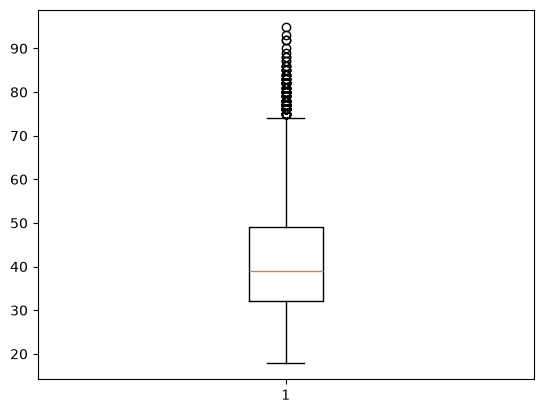

In [133]:
plt.boxplot(df['age'])
plt.show()

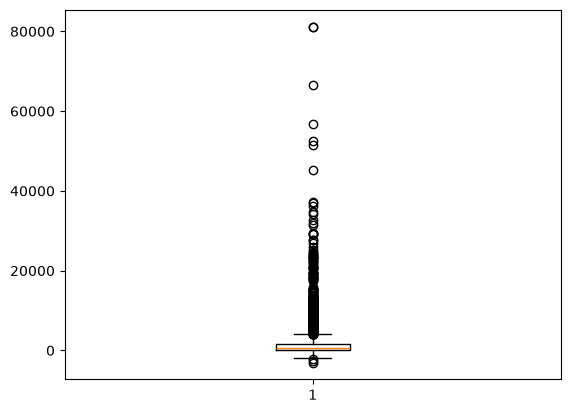

In [134]:
plt.boxplot(df['balance'])
plt.show()

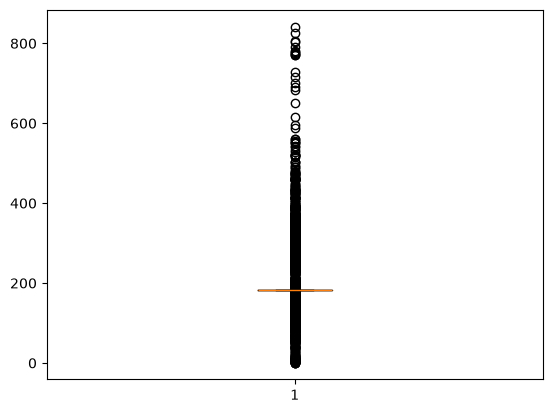

In [135]:
plt.boxplot(df['pdays'])
plt.show()

In [136]:
def remove_outliers_iqr(data, column_name="value"):
    """
    Removes outliers using the IQR method.
    Returns filtered DataFrame.
    """
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name=['balance','pdays'])

print(df.shape,cleaned_df.shape)

(8903, 44) (8903, 44)


In [137]:
X=df.drop('deposit',axis=1)
y=df['deposit']

In [138]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,
                                   test_size= 0.20, random_state=42, stratify=y)

In [139]:
from sklearn.preprocessing import StandardScaler
sca=StandardScaler()


In [140]:
X_train[['age','balance','previous','day','pdays','campaign','duration']] = sca.fit_transform(
    X_train[['age','balance','previous','day','pdays','campaign','duration']]
)

X_test[['age','balance','previous','day','pdays','campaign','duration']] = sca.transform(
    X_test[['age','balance','previous','day','pdays','campaign','duration']]
)

In [141]:
print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (7122, 43)  y_train =  (7122,)
X_test  =  (1781, 43)  y_test  =  (1781,)


In [142]:
X_train.head()

,age,balance,day,duration,campaign,pdays,previous,previously_contacted,marital_married,marital_single,default_yes,loan_yes,housing_yes,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,education_secondary,education_tertiary,education_unknown,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep
3586,-1.460729,-0.097430,0.637023,-0.173127,-0.539221,-0.516360,0.508071,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
7975,-0.866371,0.259666,0.399160,-0.591227,-0.539221,-0.091869,-0.367863,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5611,-0.696554,1.061475,1.350611,-0.605352,-0.539221,-1.495955,0.508071,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6023,0.831797,2.733140,-1.265879,-0.110977,-0.539221,-0.091869,-0.367863,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6345,-0.526737,-0.167584,0.993817,-0.557327,-0.189017,-0.091869,-0.367863,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [143]:
X_train.max()

age                      4.567765
balance                 23.980933
day                      1.826336
duration                 8.217113
campaign                21.173391
pdays                   10.422450
previous                23.720317
previously_contacted     1.000000
marital_married          1.000000
marital_single           1.000000
default_yes              1.000000
loan_yes                 1.000000
housing_yes              1.000000
contact_telephone        1.000000
contact_unknown          1.000000
poutcome_other           1.000000
poutcome_success         1.000000
poutcome_unknown         1.000000
education_secondary      1.000000
education_tertiary       1.000000
education_unknown        1.000000
job_blue-collar          1.000000
job_entrepreneur         1.000000
job_housemaid            1.000000
job_management           1.000000
job_retired              1.000000
job_self-employed        1.000000
job_services             1.000000
job_student              1.000000
job_technician

# implement the models

In [144]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report


In [145]:
model=LogisticRegression(
       C=1.0,
        max_iter=3000,
        fit_intercept=True
)

In [146]:
model.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [147]:
y_pred=model.predict(X_test)

In [148]:
score=accuracy_score(y_test,y_pred)
print(score)

0.819764177428411


In [149]:
pre=precision_score(y_test,y_pred,average='macro')
print(pre)

0.8195627768598392


In [150]:
pre=recall_score(y_test,y_pred,average='macro')
print(pre)

0.8188347808497995


In [151]:
pre=f1_score(y_test,y_pred,average='macro')
print(pre)

0.8191234605984387


In [152]:
pre=classification_report(y_test,y_pred)
print(pre)

              precision    recall  f1-score   support

          no       0.82      0.84      0.83       935
         yes       0.82      0.80      0.81       846

    accuracy                           0.82      1781
   macro avg       0.82      0.82      0.82      1781
weighted avg       0.82      0.82      0.82      1781



In [153]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report

In [154]:
models=GaussianNB()

In [155]:
models.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[3738.,3384.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.52,0.48]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U3](2,)","['no','yes']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](43,)","['age','balance','day',...,'month_nov','month_oct','month_sep']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,43
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 43)","[[-0.02,-0.06, 0.05,..., 0.09, 0.01, 0.01], [ 0.02, 0.07,-0.06,..., 0.08, 0.07, 0.05]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 43)","[[0.75,0.87,0.98,...,0.08,0.01,0.01], [1.27,1.13,1.01,...,0.07,0.06,0.05]]"


In [156]:
y_predd = models.predict(X_test)

In [157]:
score=accuracy_score(y_test,y_predd)
print(score)

0.7052217855137564


In [158]:
RS=recall_score(y_test,y_predd,average='macro')
print(RS)

0.696748460828561


In [159]:
RS=precision_score(y_test,y_predd,average='macro')
print(RS)

0.7252536509820382


In [160]:
RS=f1_score(y_test,y_predd,average='macro')
print(RS)

0.6923718483351511


In [161]:
RS=classification_report(y_test,y_predd)
print(RS)

              precision    recall  f1-score   support

          no       0.67      0.87      0.76       935
         yes       0.78      0.53      0.63       846

    accuracy                           0.71      1781
   macro avg       0.73      0.70      0.69      1781
weighted avg       0.72      0.71      0.70      1781



In [162]:
from sklearn.neighbors import KNeighborsClassifier

In [163]:
model_2=KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=3)

In [164]:
model_2.fit(X_train,y_train)

,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",3
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['no','yes']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'mi...ki'


In [165]:
y_prd=model_2.predict(X_test)

In [166]:
score=accuracy_score(y_test,y_prd)
print(score)

0.8096574957888827


In [167]:
RS=recall_score(y_test,y_prd,average='macro')
print(RS)

0.8085340261185068


In [168]:
RS=precision_score(y_test,y_prd,average='macro')
print(RS)

0.8095420796160491


In [169]:
RS=f1_score(y_test,y_prd,average='macro')
print(RS)

0.8089017689023006


In [170]:
RS=classification_report(y_test,y_prd)
print(RS)

              precision    recall  f1-score   support

          no       0.81      0.83      0.82       935
         yes       0.81      0.79      0.80       846

    accuracy                           0.81      1781
   macro avg       0.81      0.81      0.81      1781
weighted avg       0.81      0.81      0.81      1781



In [171]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [172]:
model = SVC(C=0.1, kernel='linear',gamma='auto')

model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [173]:
y_pred = model.predict(X_test)

In [174]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


0.8253790005614823
              precision    recall  f1-score   support

          no       0.83      0.84      0.83       935
         yes       0.82      0.81      0.82       846

    accuracy                           0.83      1781
   macro avg       0.83      0.82      0.82      1781
weighted avg       0.83      0.83      0.83      1781



In [175]:
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [176]:

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold

In [177]:
"""
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='accuracy',n_jobs=-1)

grid.fit(X_train, y_train)
"""

"\ngrid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='accuracy',n_jobs=-1)\n\ngrid.fit(X_train, y_train)\n"

In [178]:
"""
print(grid.best_params_)
print(grid.best_score_)
"""

'\nprint(grid.best_params_)\nprint(grid.best_score_)\n'

In [179]:
"""
best_model = grid.best_estimator_

"""

'\nbest_model = grid.best_estimator_\n\n'

In [180]:
"""
y_pred = best_model.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
"""

'\ny_pred = best_model.predict(X_test)\n\nprint(accuracy_score(y_test, y_pred))\nprint(classification_report(y_test, y_pred))\n'

In [181]:
"""
random_param = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}
"""

"\nrandom_param = {\n    'C': [0.1, 1, 10, 100],\n    'kernel': ['linear', 'rbf', 'poly'],\n    'gamma': ['auto', 'scale']\n}\n"

In [182]:
"""
random = RandomizedSearchCV(estimator=SVC(), param_distributions=random_param, cv=5, scoring='accuracy')

random.fit(X_train, y_train)
"""

"\nrandom = RandomizedSearchCV(estimator=SVC(), param_distributions=random_param, cv=5, scoring='accuracy')\n\nrandom.fit(X_train, y_train)\n"

In [183]:
"""
print(random.best_params_)
print(random.best_score_)
"""

'\nprint(random.best_params_)\nprint(random.best_score_)\n'

In [184]:
"""
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

score = cross_val_score(best_model, X_train, y_train, cv=kfold, scoring='accuracy')

print(score)
print(score.mean())
"""


"\nkfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)\n\nscore = cross_val_score(best_model, X_train, y_train, cv=kfold, scoring='accuracy')\n\nprint(score)\nprint(score.mean())\n"

In [185]:
from sklearn.tree  import DecisionTreeClassifier,plot_tree

In [186]:
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    min_impurity_decrease=0.01,
    ccp_alpha=0.01
)
    

In [187]:
model.fit(X_train,y_train)



,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",100
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.01
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.01
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consi

In [188]:
y_pred=model.predict(X_test)

In [189]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


0.7754070746771476
              precision    recall  f1-score   support

          no       0.84      0.71      0.77       935
         yes       0.72      0.85      0.78       846

    accuracy                           0.78      1781
   macro avg       0.78      0.78      0.78      1781
weighted avg       0.78      0.78      0.77      1781



Decision Tree - Plotting the tree


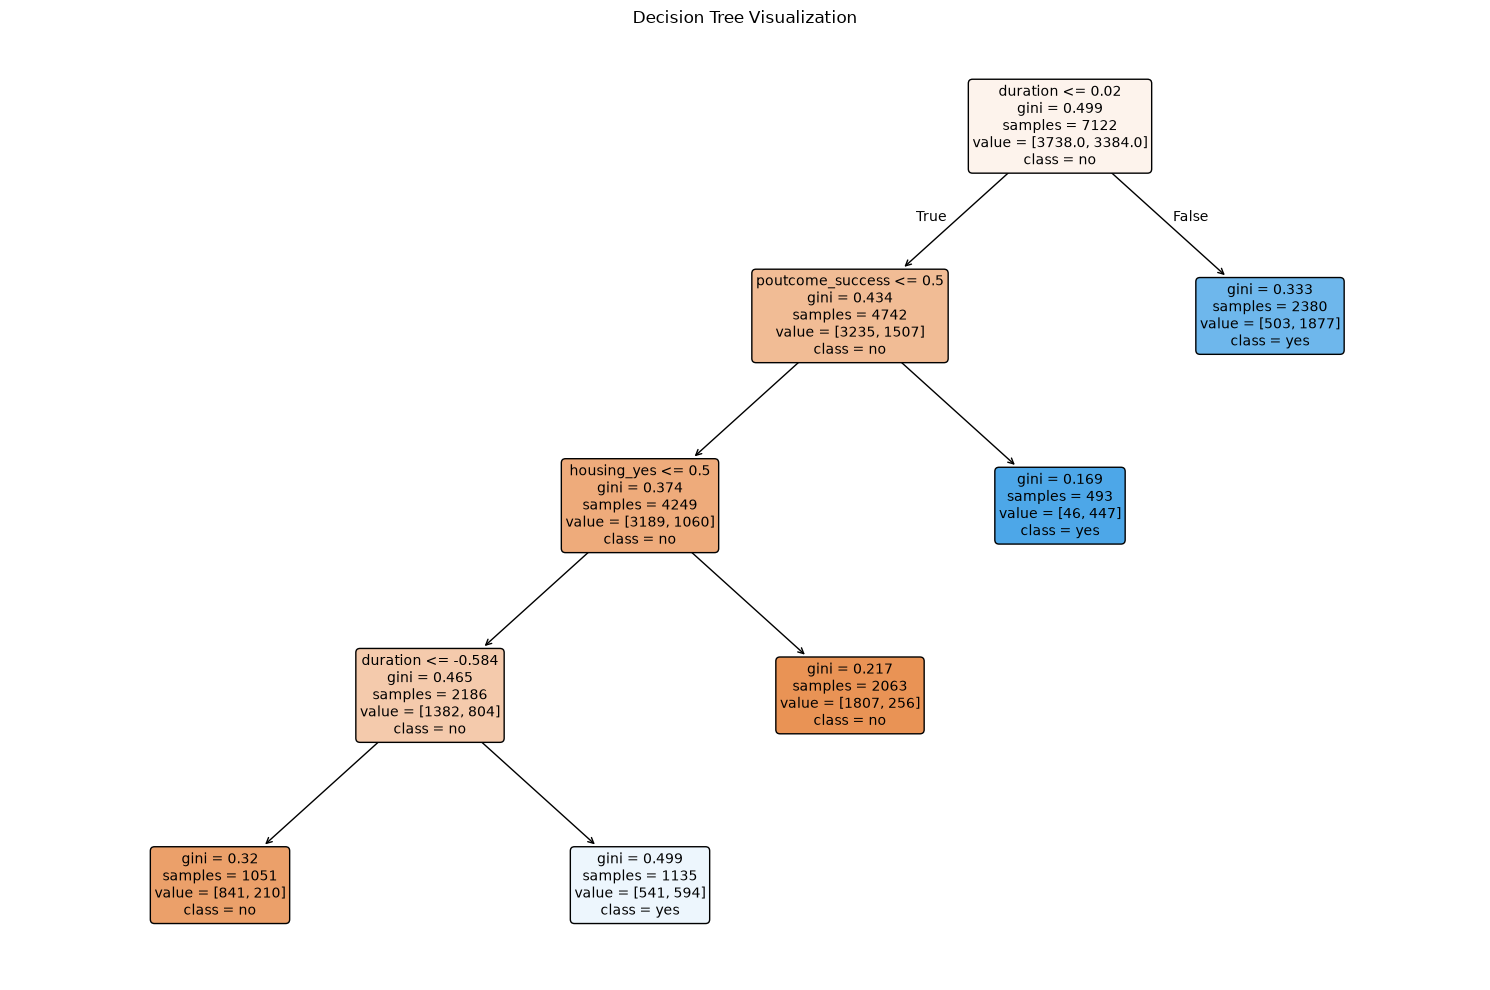

In [ ]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [194]:
grid_params = {
   'criterion': ["gini","entropy"],       
    'random_state':[100,"None"],
       'max_depth': [10,100],
}

In [195]:
grid = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(X_train, y_train)

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
20 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Us

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [10, 100], 'random_state': [100, 'None']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [196]:
print(grid.best_params_)
print(grid.best_score_)

{'criterion': 'gini', 'max_depth': 10, 'random_state': 100}
0.8171841119653065


In [197]:
best_model = grid.best_estimator_


In [199]:
y_pred = best_model.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8062886019090398
              precision    recall  f1-score   support

          no       0.83      0.80      0.81       935
         yes       0.78      0.82      0.80       846

    accuracy                           0.81      1781
   macro avg       0.81      0.81      0.81      1781
weighted avg       0.81      0.81      0.81      1781



In [209]:
from sklearn.tree import DecisionTreeClassifier

rf = DecisionTreeClassifier (random_state=42)
rf.fit(X_train, y_train)

# Get top 10 important features
importances = pd.Series(rf.feature_importances_,index=X.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("Random Forest Selected Features:",selected_columns.tolist())
selected_features = importances.nlargest(5)
print("Random Forest Selected Features:", selected_features.tolist())

Random Forest Selected Features: ['duration', 'poutcome_success', 'day', 'balance', 'age']
Random Forest Selected Features: [0.3326514797840353, 0.11085734332573799, 0.0845488527278221, 0.06882064356282534, 0.06446447131490479]


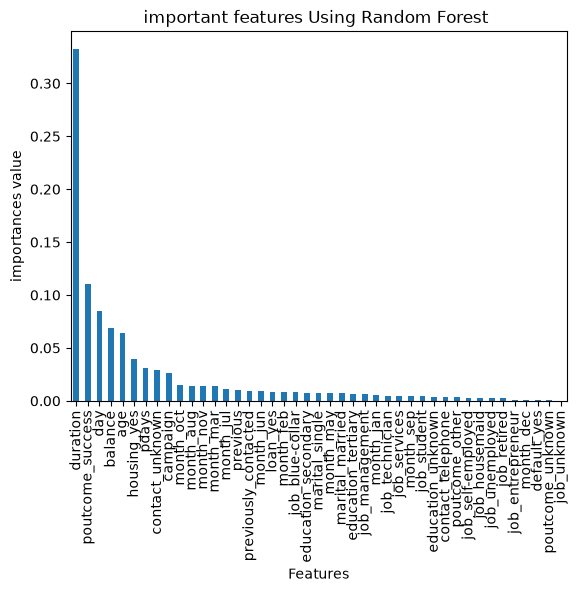

In [212]:
plt.Figure(figsize=(20,12))
importances.plot(kind='bar')
plt.title("important features Using Random Forest ")
plt.xlabel("Features")
plt.ylabel("importances value")
plt.show()